In [ ]:
!wget -O 20news.tar.gz http://qwone.com/~jason/20Newsgroups/20news-bydate.tar.gz

--2026-09-05 17:14:26--  http://qwone.com/~jason/20Newsgroups/20news-bydate.tar.gz
Resolving qwone.com (qwone.com)... 173.48.205.131
Connecting to qwone.com (qwone.com)|173.48.205.131|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14464277 (14M) [application/x-gzip]
Saving to: ‘20news.tar.gz’

20news.tar.gz       100%[===================>]  13.79M  7.99MB/s    in 1.7s    

2026-09-05 17:14:28 (7.99 MB/s) - ‘20news.tar.gz’ saved [14464277/14464277]



In [ ]:
!tar -xzf 20news.tar.gz

In [ ]:
from sklearn.datasets import load_files

train_data = load_files(
    "20news-bydate-train",
    encoding="utf-8",
    decode_error="replace"
)

print(train_data.keys())

dict_keys(['data', 'filenames', 'target_names', 'target', 'DESCR'])


In [ ]:
# Install required libraries
!pip install -q scikit-learn pandas matplotlib seaborn

Dataset already downloaded.
Dataset already extracted.
Training samples:  11314
Testing samples:  7532
No. of classes:  20
0: alt.atheism
1: comp.graphics
2: comp.os.ms-windows.misc
3: comp.sys.ibm.pc.hardware
4: comp.sys.mac.hardware
5: comp.windows.x
6: misc.forsale
7: rec.autos
8: rec.motorcycles
9: rec.sport.baseball
10: rec.sport.hockey
11: sci.crypt
12: sci.electronics
13: sci.med
14: sci.space
15: soc.religion.christian
16: talk.politics.guns
17: talk.politics.mideast
18: talk.politics.misc
19: talk.religion.misc


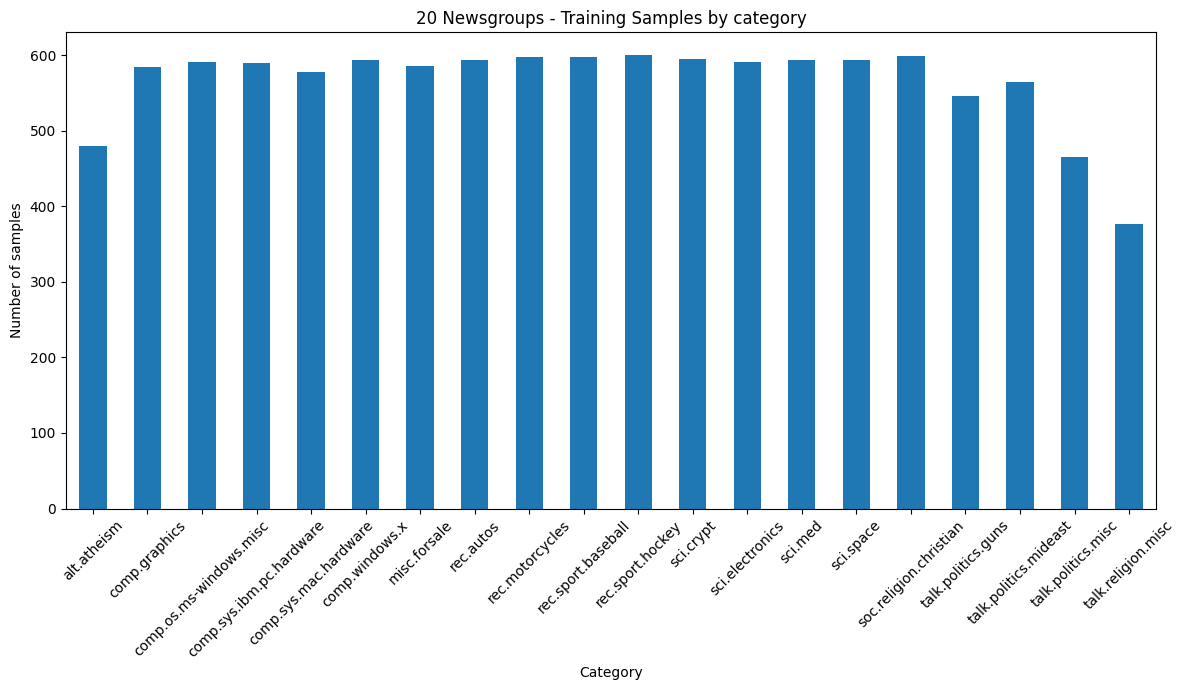

Training TF-IDF shape:  (11314, 56118)
Testing TF_IDF shape:  (7532, 56118)
Training model...
Training complete
Accuracy: 85.33%
                          precision    recall  f1-score   support

             alt.atheism       0.80      0.77      0.78       319
           comp.graphics       0.73      0.81      0.77       389
 comp.os.ms-windows.misc       0.79      0.78      0.78       394
comp.sys.ibm.pc.hardware       0.73      0.78      0.75       392
   comp.sys.mac.hardware       0.84      0.85      0.84       385
          comp.windows.x       0.87      0.78      0.82       395
            misc.forsale       0.81      0.89      0.85       390
               rec.autos       0.92      0.91      0.92       396
         rec.motorcycles       0.97      0.96      0.97       398
      rec.sport.baseball       0.92      0.94      0.93       397
        rec.sport.hockey       0.95      0.97      0.96       399
               sci.crypt       0.96      0.92      0.94       396
         sci

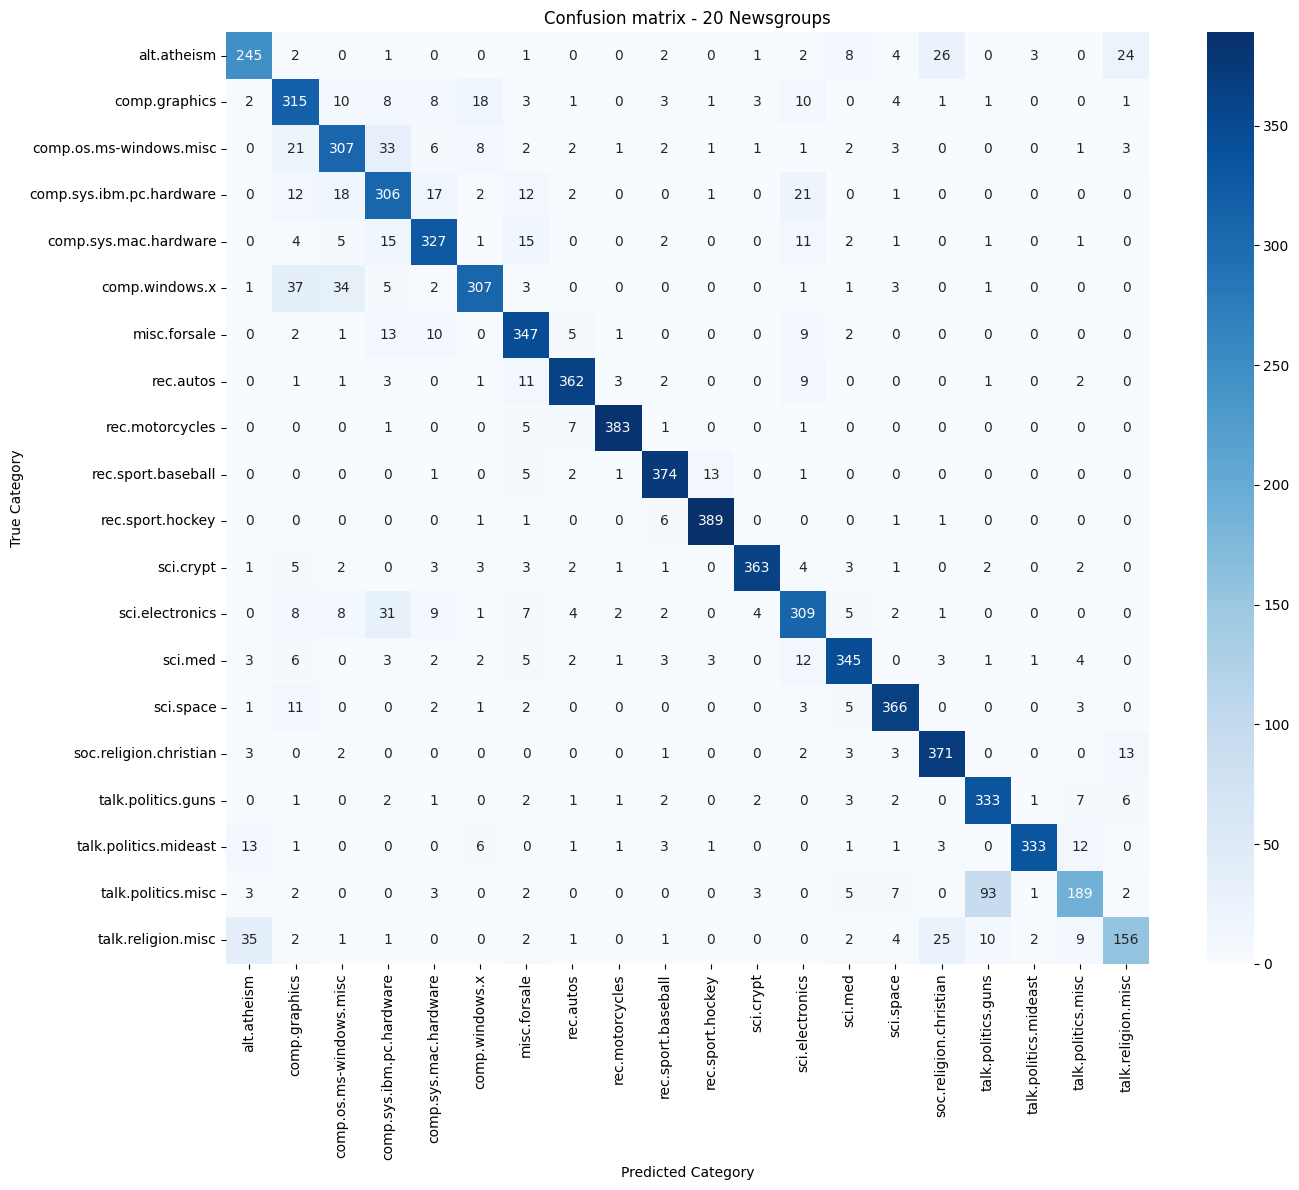

Enter a news headline: Nasa has stopped the exploration of deep sea
Predicted category: 
sci.space


In [6]:
import os
import tarfile
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_files
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import(
    classification_report,
    confusion_matrix,
    accuracy_score
)
from sklearn.linear_model import LogisticRegression

url = "http://qwone.com/~jason/20Newsgroups/20news-bydate.tar.gz"
file_name = '20news-bydatej.tar.gz'

if not os.path.exists(file_name):
    print('Downloading dataset...')
    urllib.request.urlretrieve(url,file_name)
    print('Download complete.')

else:
  print('Dataset already downloaded.')

if not os.path.exists('20news-bydate-train'):
    with tarfile.open(file_name,'r:gz') as tar:
      tar.extractall()

    print('Dataset extracted')

else:
    print('Dataset already extracted.')


#Loading training and testing data

train_data = load_files(
    '20news-bydate-train',
    encoding='utf-8',
    decode_error='replace'
)

test_data = load_files(
    '20news-bydate-test', # Corrected from '20news-bydata-test'
    encoding='utf-8',
    decode_error='replace'
)

X_train = train_data.data
y_train = train_data.target

X_test = test_data.data
y_test = test_data.target

target_names = train_data.target_names


print('Training samples: ',len(X_train))
print('Testing samples: ',len(X_test))
print('No. of classes: ',len(target_names))

for i, category in enumerate(target_names):
    print(f"{i}: {category}")

df_train = pd.DataFrame({
    'text': X_train,
    'target':y_train
})
df_train['category'] = df_train['target'].map(
    lambda x: target_names[x]
)
df_train.head()

#data visualization

class_counts = df_train['category'].value_counts().sort_index()

plt.figure(figsize=(12,7))

class_counts.plot(kind='bar')

plt.title('20 Newsgroups - Training Samples by category')
plt.xlabel('Category')
plt.ylabel('Number of samples')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

#vectorizing text

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words='english',
    max_df=0.95,
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training TF-IDF shape: ",X_train_tfidf.shape)
print("Testing TF_IDF shape: ",X_test_tfidf.shape)


#classification

model = LogisticRegression(
    max_iter=1000,
    C=4
)

print("Training model...")
model.fit(X_train_tfidf,y_train)
print("Training complete")

y_pred = model.predict(X_test_tfidf)

#checking accuracy

accuracy = accuracy_score(y_test,y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

print(classification_report(
    y_test,
    y_pred,
    target_names=target_names
))


#Classified visualization

cm = confusion_matrix(y_test,y_pred)

plt.figure(figsize=(14,12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_names,
    yticklabels=target_names
)

plt.title("Confusion matrix - 20 Newsgroups")
plt.xlabel("Predicted Category")
plt.ylabel("True Category")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

#Individual predictions

results = pd.DataFrame({
    'actual': [
        target_names[i] for i in y_test
    ],
    'predicted':[
        target_names[i] for i in y_pred
    ]
})
results.head(10)


#Making a prediction

def predict_category(text):
    text_vector = vectorizer.transform([text])

    prediction = model.predict(text_vector)[0]

    return target_names[prediction]

text = input("Enter a news headline: ")

print("Predicted category: ")
print(predict_category(text))
